In [116]:
import pandas as pd

In [117]:
iris = pd.read_csv('iris.csv')

In [118]:
iris.head()

,id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [119]:
iris.shape

(150, 6)

In [120]:
iris.describe()

,id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [121]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [122]:
iris['Species'].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

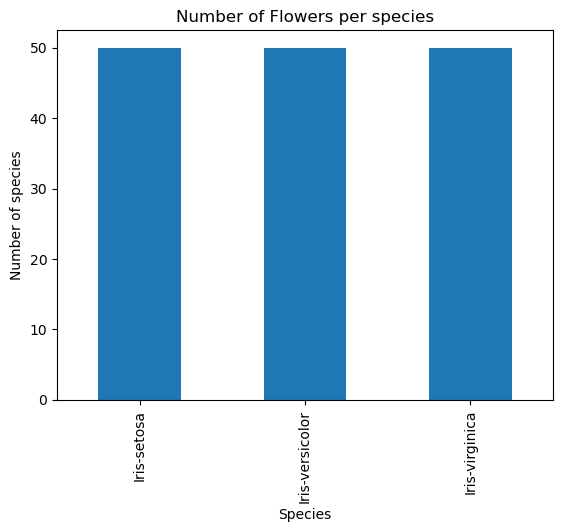

In [123]:
import matplotlib.pyplot as plt
iris['Species'].value_counts().plot(kind="bar")

plt.title("Number of Flowers per species")
plt.xlabel("Species")
plt.ylabel("Number of species")
plt.show()

In [124]:
iris.groupby("Species")[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]].mean()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


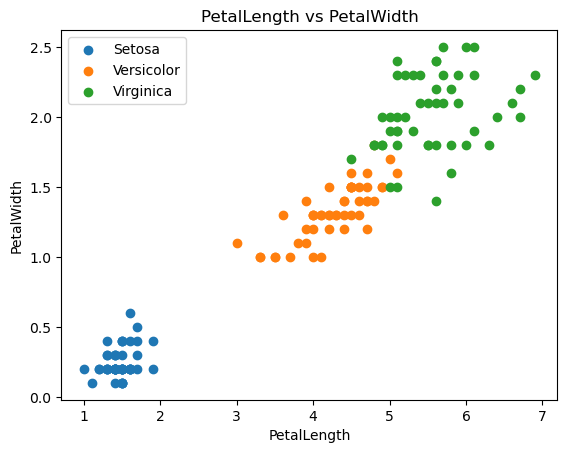

In [125]:
plt.scatter(
    iris[iris['Species'] == 'Iris-setosa']['PetalLengthCm'],
    iris[iris['Species'] == 'Iris-setosa']['PetalWidthCm'],
    label="Setosa"
)
plt.scatter(
    iris[iris['Species'] == 'Iris-versicolor']['PetalLengthCm'],
    iris[iris['Species'] == 'Iris-versicolor']['PetalWidthCm'],
    label="Versicolor"
)
plt.scatter(
    iris[iris['Species'] == 'Iris-virginica']['PetalLengthCm'],
    iris[iris['Species'] == 'Iris-virginica']['PetalWidthCm'],
    label="Virginica"
)

plt.title("PetalLength vs PetalWidth")
plt.xlabel("PetalLength")
plt.ylabel("PetalWidth")
plt.legend()
plt.show()

In [126]:
iris_clean = iris.drop(columns=["id"])

In [127]:
iris_clean.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [128]:
X = iris_clean[
    ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
]
y = iris_clean["Species"]

In [129]:
X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [130]:
y.head()

0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object

In [131]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=18
)

In [132]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(120, 4)
(30, 4)
(120,)
(30,)


In [133]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)

In [134]:
model.fit(X_train, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [135]:
y_pred = model.predict(X_test)

In [136]:
y_pred

array(['Iris-versicolor', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-setosa', 'Iris-setosa', 'Iris-setosa', 'Iris-virginica',
       'Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-virginica', 'Iris-versicolor', 'Iris-setosa',
       'Iris-virginica', 'Iris-setosa', 'Iris-versicolor', 'Iris-setosa',
       'Iris-virginica', 'Iris-setosa', 'Iris-setosa', 'Iris-versicolor',
       'Iris-virginica', 'Iris-virginica', 'Iris-versicolor',
       'Iris-virginica', 'Iris-setosa', 'Iris-setosa', 'Iris-setosa',
       'Iris-virginica', 'Iris-virginica'], dtype=object)

In [137]:
pd.Series(y_pred).value_counts()

Iris-setosa        12
Iris-virginica     10
Iris-versicolor     8
Name: count, dtype: int64

In [138]:
y_test

81     Iris-versicolor
92     Iris-versicolor
80     Iris-versicolor
4          Iris-setosa
30         Iris-setosa
24         Iris-setosa
129     Iris-virginica
41         Iris-setosa
102     Iris-virginica
87     Iris-versicolor
144     Iris-virginica
54     Iris-versicolor
18         Iris-setosa
109     Iris-virginica
33         Iris-setosa
56     Iris-versicolor
17         Iris-setosa
105     Iris-virginica
6          Iris-setosa
37         Iris-setosa
74     Iris-versicolor
149     Iris-virginica
123     Iris-virginica
65     Iris-versicolor
114     Iris-virginica
48         Iris-setosa
45         Iris-setosa
0          Iris-setosa
112     Iris-virginica
116     Iris-virginica
Name: Species, dtype: object

In [139]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"{accuracy*100}%")

100.0%


In [140]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[12  0  0]
 [ 0  8  0]
 [ 0  0 10]]


In [148]:
new_flower = pd.DataFrame(
    [[3.1, 2.5, 2.4, 1.2]],
    columns = [
        "SepalLengthCm",
        "SepalWidthCm",
        "PetalLengthCm",
        "PetalWidthCm"
    ]
)

In [149]:
prediction = model.predict(new_flower)

print(prediction)

['Iris-setosa']
